# Лабораторная работа №5

## Цели и задачи

Выполнить массовое статистическое моделирование, направленное на
изучение статистических свойств разных точечных оценок математического ожидания и
дисперсии, сравнение с теоретически ожидаемыми свойствами, верная статистическая
интерпретация результатов.

## Задание 1

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


n_arr = np.arange(10, 110, 10)
sns.set_style('whitegrid')
mean_cmp = []
var_mean_cmp = []
var_cmp = []
var_var_cmp = []
var_bias_cmp = []
var_var_bias_cmp = []
for n in n_arr:
    mean_arr = []
    var_bias_arr = []
    var_arr = []
    for _ in range(1000):
        data = np.random.normal(size=n)
        mean_arr.append(np.mean(data))
        var_arr.append(np.var(data, ddof=1))
        var_bias_arr.append(np.var(data, ddof=0))
    mean_cmp.append(np.mean(mean_arr))
    var_cmp.append(np.mean(var_arr))
    var_bias_cmp.append(np.mean(var_bias_arr))
    
    var_mean_cmp.append(np.var(mean_arr, ddof=1))
    var_var_cmp.append(np.var(var_arr, ddof=1))
    var_var_bias_cmp.append(np.var(var_bias_arr, ddof=1))

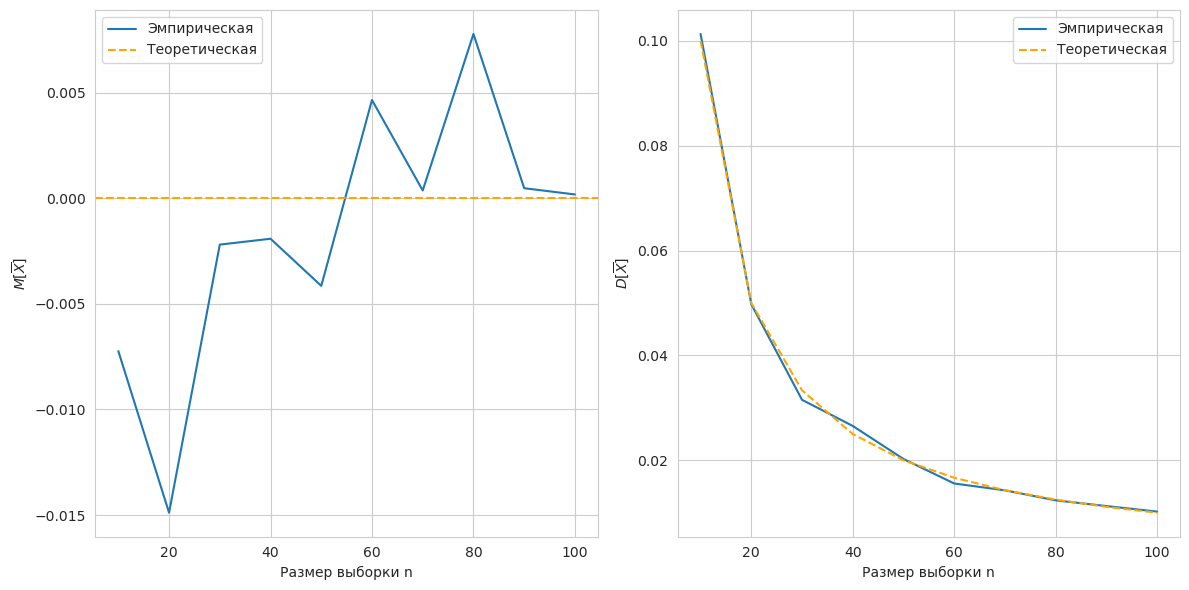

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

sns.lineplot(x=n_arr, y=mean_cmp, label='Эмпирическая', ax=axes[0])
axes[0].set_xlabel('Размер выборки n')
axes[0].set_ylabel(r'$M[\overline{X}]$')
axes[0].axhline(y=0, label='Теоретическая', color='orange', linestyle='--')
axes[0].legend()

sns.lineplot(x=n_arr, y=var_mean_cmp, label='Эмпирическая', ax=axes[1])
axes[1].set_xlabel('Размер выборки n')
axes[1].set_ylabel(r'$D[\overline{X}]$')
axes[1].plot(n_arr, [1/n for n in n_arr], label='Теоретическая', color='orange', linestyle='--')
axes[1].legend()

plt.tight_layout()
plt.show()

Необходимо вывести $Var[\hat{\sigma_{unb}}^2]$ и $Var[\hat{\sigma_{b}}^2]$

$$\frac{\hat{\sigma_{unb}}^2 (n-1)}{\sigma^2} \sim \chi_{n-1}^2$$ где $\hat{\sigma_{unb}}^2$ -- несмещённая дисперсия

$$\hat{\sigma_{unb}^2} \sim \frac{1}{n-1} \chi_{n-1}^2$$

$$Var[\hat{\sigma_{unb}^2}] = \frac{1}{(n-1)^2} Var[\chi_{n-1}^2] = \frac{2 (n-1)}{(n-1)^2} = \frac{2}{n-1}$$

$$\hat{\sigma_{b}}^2 \sim \frac{1}{n} \chi_{n-1}^2$$

$$Var[\hat{\sigma_{b}^2}] = \frac{1}{n^2} Var[\chi_{n-1}^2] = \frac{2 (n-1)}{n^2}$$

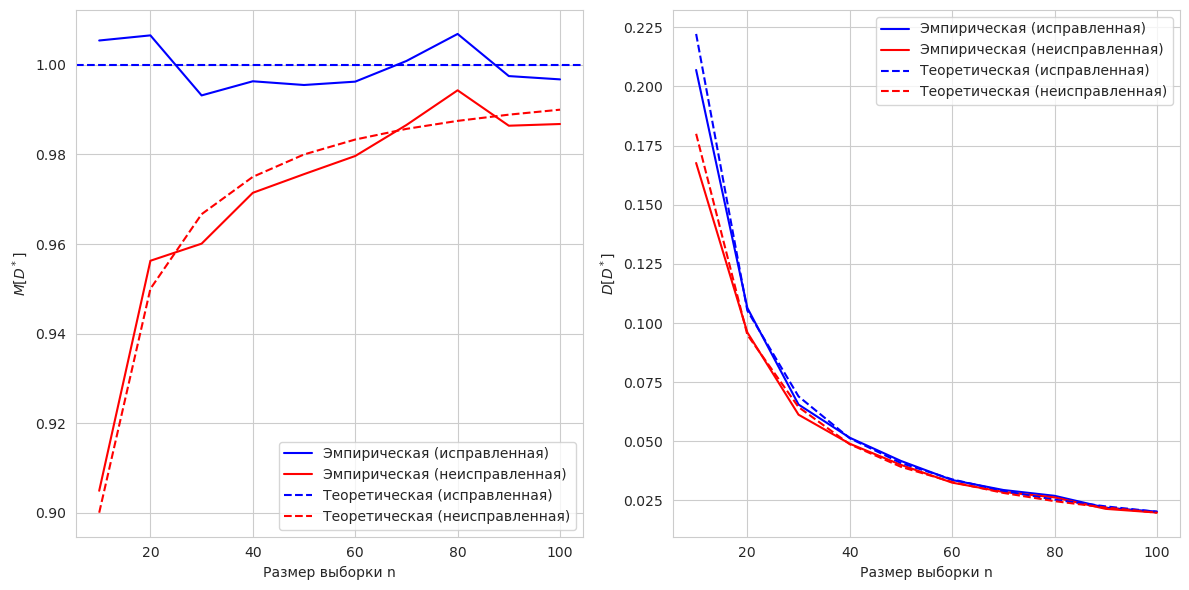

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

sns.lineplot(x=n_arr, y=var_cmp, ax=axes[0], label='Эмпирическая (исправленная)', color='blue')
sns.lineplot(x=n_arr, y=var_bias_cmp, ax=axes[0], label='Эмпирическая (неисправленная)', color='red')
axes[0].set_xlabel('Размер выборки n')
axes[0].set_ylabel(r'$M[D^*]$')
axes[0].axhline(y=1, label='Теоретическая (исправленная)', color='blue', linestyle='--')
axes[0].plot(n_arr, [(n-1)/n for n in n_arr], label='Теоретическая (неисправленная)', color='red', linestyle='--')
axes[0].legend()

sns.lineplot(x=n_arr, y=var_var_cmp, ax=axes[1], label='Эмпирическая (исправленная)', color='blue')
sns.lineplot(x=n_arr, y=var_var_bias_cmp, ax=axes[1], label='Эмпирическая (неисправленная)', color='red')
axes[1].set_xlabel('Размер выборки n')
axes[1].set_ylabel(r'$D[D^*]$')
axes[1].plot(n_arr, [2/(n-1) for n in n_arr], label='Теоретическая (исправленная)', color='blue', linestyle='--')
axes[1].plot(n_arr, [2*(n-1)/n**2 for n in n_arr], label='Теоретическая (неисправленная)', color='red', linestyle='--')
axes[1].legend()

plt.tight_layout()
plt.show()

## Задание 2

Стоит отметить, что $$\overline{X} \sim \mathcal{N}(\mathbb{E}[\overline{X}], \frac{\sigma^2}{n}) = \mathcal{N}(0, \frac{1}{n})$$

$$\frac{\hat{\sigma_{unb}}^2 (n-1)}{\sigma^2} \sim \chi_{n-1}^2$$ где $\hat{\sigma_{unb}}^2$ -- несмещённая дисперсия

$$\hat{\sigma_{unb}}^2 \sim \frac{1}{n-1} \chi_{n-1}^2$$

Пусть $$r \sim \frac{1}{n-1} \chi_{n-1}^2$$

Тогда

$$P(r < x) = P(r (n-1) < x (n-1)) = F_{\chi_{n-1}^2} (x (n-1))$$

Таким образом, $$F_{\hat{\sigma_{unb}}^2}(x) = F_{\chi_{n-1}^2} (x (n-1))$$

Так как $$\hat{\sigma_{unb}}^2 = \hat{\sigma_{b}}^2 \frac{n}{n-1}$$

Тогда $$\hat{\sigma_{b}}^2 \frac{n}{n-1} \frac{n-1}{\sigma^2} \sim \chi_{n-1}^2$$

$$\hat{\sigma_{b}}^2 \sim \frac{1}{n} \chi_{n-1}^2$$

Следовательно, $$F_{\hat{\sigma_{b}}^2}(x) = F_{\chi_{n-1}^2} (xn)$$

In [4]:
from scipy.stats import norm, chi2


def collect_data(n):
    mean_arr = []
    var_arr = []
    var_bias_arr = []
    for _ in range(1000):
        data = np.random.normal(size=n)
        mean_arr.append(np.mean(data))
        var_arr.append(np.var(data, ddof=1))
        var_bias_arr.append(np.var(data, ddof=0))
    return mean_arr, var_arr, var_bias_arr

def plot_cdf(mean_arr, var_arr, var_bias_arr, n):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    x_line = np.arange(-2, 2, 0.01)
    theory_fd = norm.cdf(x_line, loc=0, scale=1/np.sqrt(n))
    sns.ecdfplot(mean_arr, ax=axes[0], label='Empirical', color='blue')
    sns.lineplot(x=x_line, y=theory_fd, label='Theoretical', ax=axes[0], color='orange')
    axes[0].set_title('DF for estimate of the expected value')
    
    sns.ecdfplot(var_arr, ax=axes[1], label='Empirical', color='blue')
    x_line = np.arange(0, 5, 0.01)
    sns.lineplot(x=x_line, y=chi2.cdf((n-1) * x_line, df=n-1), ax=axes[1], color='orange', label='Theoretical')
    axes[1].set_title('DF for estimate of the unbiased variance')
    
    sns.ecdfplot(var_bias_arr, ax=axes[2], label='Empirical', color='blue')
    sns.lineplot(x=x_line, y=chi2.cdf(n * x_line, df=n-1), ax=axes[2],color='orange', label='Theoretical')
    axes[2].set_title('DF for estimate of the biased variance')
    
    for i in range(3):
        axes[i].legend()
    plt.tight_layout()
    plt.show()

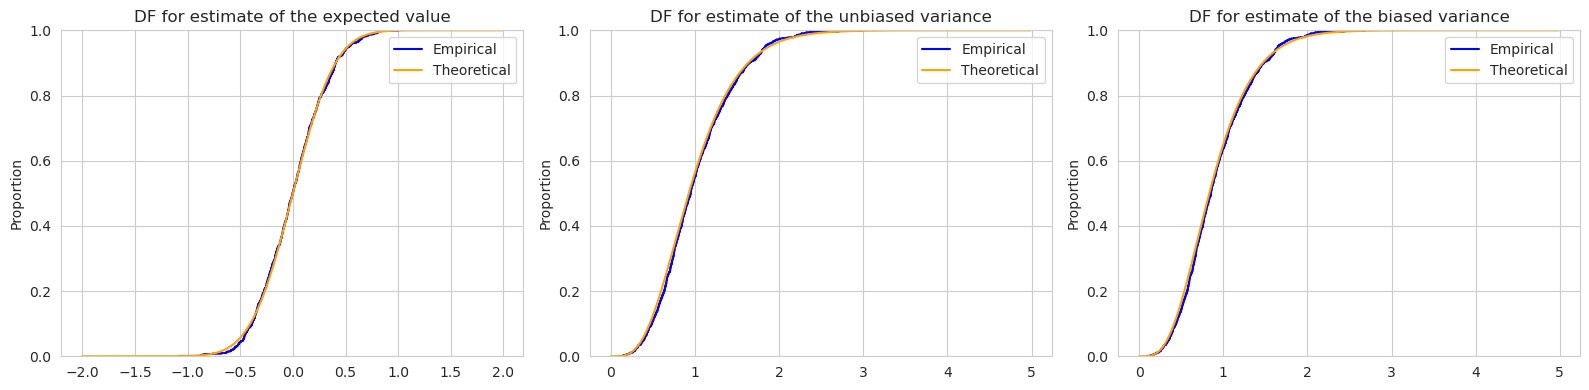

In [5]:
mean_arr, var_arr, var_bias_arr = collect_data(10)
plot_cdf(mean_arr, var_arr, var_bias_arr, 10)

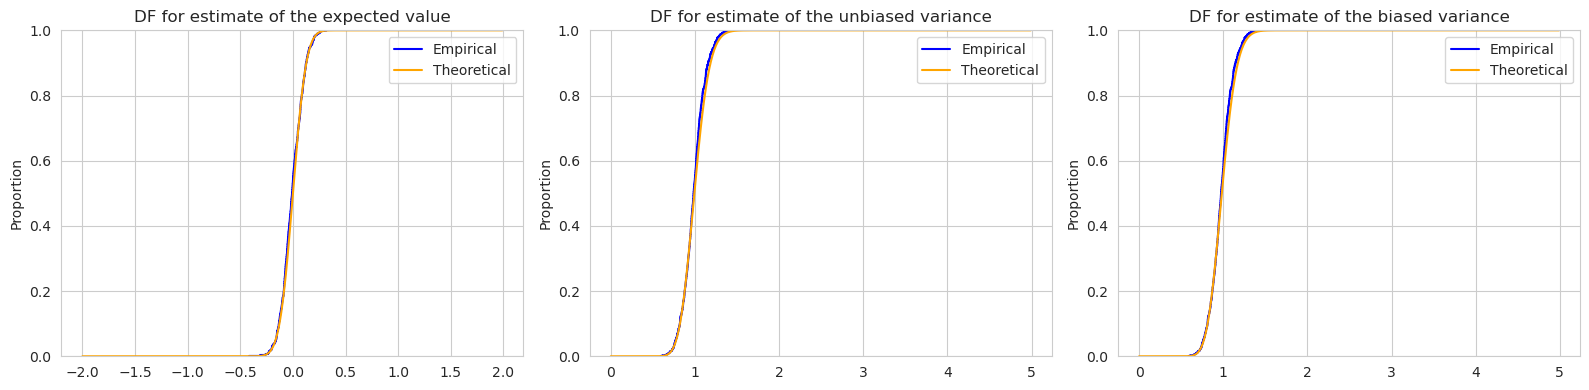

In [6]:
mean_arr, var_arr, var_bias_arr = collect_data(100)
plot_cdf(mean_arr, var_arr, var_bias_arr, 100)

## Выводы

1. Построены графики зависимостей матожиданий и дисперсий оцениваемых параметров. На основе полученных данных можно сделать вывод, что имеет место сходимость эмпирических данных с теоретическими.
2. Построены функции распределения для оцениваемых параметров и теоретические функции распределения. Исходя из полученных графиков можно сделать вывод, что эмпирические данные близки к теоретическим.